In [1]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import optuna
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


c:\Users\pc\my_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

SEED = 42
N_SPLITS = 5
TEST_SIZE = 0.2
VAL_SIZE = 0.15
N_JOBS = -1
N_TRIALS = 20
TARGET_COL = "duty_HT1"
LEAK_COLS = ["Q_HT1_kW"]
DROP_COLS = ["converged", "status", "mass_balance_err", "P_reb_barg", "P_top_barg"]
MIN_STD = 1e-4

In [3]:
GRAPH_TOPK = 3
GRAPH_MIN_CORR = 0.30

GNN_HIDDEN = 32
GNN_LAYERS = 2
GNN_DROPOUT = 0.1
GNN_EPOCHS = 600
GNN_LR = 3e-3
GNN_WD = 1e-4
GNN_BATCH = 32
GNN_PATIENCE = 60

In [4]:

DATA_CSV = r"C:\Users\pc\Desktop\project\simulation chaine porduciton de ciment\data_final_v4_clean.csv"
OUT_DIR = r"C:\Users\pc\Desktop\project\simulation chaine porduciton de ciment\resultats_ml"

In [5]:
TWO_MODELS = ("XGBoost", "LightGBM")

CYAN, PURPLE, YELLOW = "#0CF7AF", "#D826F8", "#F7C53E"



In [6]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)


def save_fig(name):
    path = os.path.join(OUT_DIR, name)
    plt.savefig(path, dpi=130, bbox_inches="tight")
    plt.close()
    print("  figure:", path)

# cleaning_data

In [7]:

def load_data():
    raw = pd.read_csv(DATA_CSV)
    print(f"CSV brut: {raw.shape[0]} lignes, {raw.shape[1]} colonnes")
    if "status" in raw.columns:
        print("Statuts:", raw["status"].value_counts().to_dict())
    df = raw.copy()
    if "converged" in df.columns:
        df = df[df["converged"] == 1]
    if "status" in df.columns:
        df = df[df["status"] == "ok"]
    df = df.drop(columns=[c for c in LEAK_COLS + DROP_COLS if c in df.columns])
    df = df.select_dtypes(include=[np.number]).dropna().drop_duplicates().reset_index(drop=True)
    if TARGET_COL not in df.columns:
        raise SystemExit(f"Colonne cible '{TARGET_COL}' absente du CSV")
    low_var = [c for c in df.columns if c != TARGET_COL and df[c].std() < MIN_STD]
    if low_var:
        print("Colonnes quasi constantes retirees:", low_var)
        df = df.drop(columns=low_var)
    print(f"Dataset utilisable: {df.shape[0]} lignes, {df.shape[1] - 1} features\n")
    if len(df) < 500:
        print("[attention] moins de 500 points : les resultats ML/GNN seront peu stables.\n")
    
    return df

In [8]:
load_data()

CSV brut: 1470 lignes, 30 colonnes
Statuts: {'ok': 1470}
Colonnes quasi constantes retirees: ['TOP_N-hexane', 'BOT_Ethane']
Dataset utilisable: 1470 lignes, 21 features



,reflux_ratio,feed_total_kg_h,duty_HT1,P_cond_barg,F16_kg_h,T16_C,Q_cond_kW,Q_reb_kW,TOP_Ethane,TOP_Propane,...,TOP_Isopentane,TOP_N-pentane,BOT_Propane,BOT_Isobutane,BOT_N-butane,BOT_Isopentane,BOT_N-pentane,BOT_N-hexane,TOP_T_C,BOT_T_C
0,3.374108,180571.509295,7146.094268,19.106295,173087.300021,144.653069,23786.436487,13767.327063,0.014656,0.777642,...,0.000011,0.000003,0.000172,0.022575,0.156745,0.110008,0.088204,0.622296,60.619852,179.895265
1,2.474566,203350.201965,7774.825907,18.624114,194921.876404,138.768076,24349.640136,15643.675658,0.013308,0.706262,...,0.000091,0.000026,0.000036,0.006047,0.070046,0.123774,0.099299,0.700798,62.718209,188.590056
2,2.117197,172595.278470,7453.086135,18.864039,165441.662770,148.255844,16194.141837,3988.190421,0.015176,0.717552,...,0.009273,0.003604,0.095408,0.041097,0.092145,0.095764,0.080659,0.594807,62.884041,164.290932
3,2.037713,199822.829940,7387.037724,19.356145,191540.704576,138.925003,20248.094473,11972.695111,0.013482,0.715290,...,0.000901,0.000281,0.000271,0.015494,0.077805,0.120551,0.097238,0.688641,64.302126,189.084949
4,3.372208,176901.464139,7628.114913,18.685530,169569.368485,147.127229,22982.843021,11913.724923,0.014936,0.792328,...,0.000009,0.000002,0.000354,0.030304,0.165507,0.107774,0.086412,0.609648,58.848046,176.765752
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,2.855999,168074.204600,7875.448405,18.899554,161107.975399,154.697657,18378.245112,5813.826820,0.015709,0.776494,...,0.000050,0.000014,0.055080,0.045911,0.135329,0.102358,0.082090,0.579230,60.065617,167.551721
1466,2.591288,196253.570845,7083.304851,18.711798,188119.381788,139.304137,23440.568421,14780.538350,0.013669,0.725353,...,0.000053,0.000015,0.000067,0.010544,0.097692,0.119506,0.095849,0.676341,62.032794,185.667150
1467,3.093387,172545.079972,7719.261180,19.219366,165393.544866,148.920918,20160.335561,8777.414582,0.015299,0.805577,...,0.000017,0.000005,0.006438,0.046888,0.162644,0.105112,0.084282,0.594636,59.709347,175.656897
1468,2.432039,176386.753139,7164.952026,19.218466,169075.990888,146.176959,17959.900374,7222.881240,0.014977,0.763507,...,0.000135,0.000040,0.033138,0.043653,0.121886,0.107328,0.086121,0.607875,61.598469,174.511186


In [9]:
df = load_data()

CSV brut: 1470 lignes, 30 colonnes
Statuts: {'ok': 1470}
Colonnes quasi constantes retirees: ['TOP_N-hexane', 'BOT_Ethane']
Dataset utilisable: 1470 lignes, 21 features



In [10]:
df.head()

,reflux_ratio,feed_total_kg_h,duty_HT1,P_cond_barg,F16_kg_h,T16_C,Q_cond_kW,Q_reb_kW,TOP_Ethane,TOP_Propane,...,TOP_Isopentane,TOP_N-pentane,BOT_Propane,BOT_Isobutane,BOT_N-butane,BOT_Isopentane,BOT_N-pentane,BOT_N-hexane,TOP_T_C,BOT_T_C
0,3.374108,180571.509295,7146.094268,19.106295,173087.300021,144.653069,23786.436487,13767.327063,0.014656,0.777642,...,0.000011,0.000003,0.000172,0.022575,0.156745,0.110008,0.088204,0.622296,60.619852,179.895265
1,2.474566,203350.201965,7774.825907,18.624114,194921.876404,138.768076,24349.640136,15643.675658,0.013308,0.706262,...,0.000091,0.000026,0.000036,0.006047,0.070046,0.123774,0.099299,0.700798,62.718209,188.590056
2,2.117197,172595.278470,7453.086135,18.864039,165441.662770,148.255844,16194.141837,3988.190421,0.015176,0.717552,...,0.009273,0.003604,0.095408,0.041097,0.092145,0.095764,0.080659,0.594807,62.884041,164.290932
3,2.037713,199822.829940,7387.037724,19.356145,191540.704576,138.925003,20248.094473,11972.695111,0.013482,0.715290,...,0.000901,0.000281,0.000271,0.015494,0.077805,0.120551,0.097238,0.688641,64.302126,189.084949
4,3.372208,176901.464139,7628.114913,18.685530,169569.368485,147.127229,22982.843021,11913.724923,0.014936,0.792328,...,0.000009,0.000002,0.000354,0.030304,0.165507,0.107774,0.086412,0.609648,58.848046,176.765752


In [11]:
df.columns

Index(['reflux_ratio', 'feed_total_kg_h', 'duty_HT1', 'P_cond_barg',
       'F16_kg_h', 'T16_C', 'Q_cond_kW', 'Q_reb_kW', 'TOP_Ethane',
       'TOP_Propane', 'TOP_Isobutane', 'TOP_N-butane', 'TOP_Isopentane',
       'TOP_N-pentane', 'BOT_Propane', 'BOT_Isobutane', 'BOT_N-butane',
       'BOT_Isopentane', 'BOT_N-pentane', 'BOT_N-hexane', 'TOP_T_C',
       'BOT_T_C'],
      dtype='object')

# data visualisation and analyst 

In [ ]:
def eda(df):
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "nunique": df.nunique(),
        "mean": df.mean(),
        "std": df.std(),
        "min": df.min(),
        "max": df.max(),
    })
    print("EDA")
    print(summary.round(4).to_string())
    print("Doublons:", int(df.duplicated().sum()), "\n")
    plt.figure(figsize=(7, 4))
    sns.histplot(df[TARGET_COL], kde=True, color=CYAN)
    plt.xlabel(f"{TARGET_COL} (kW)")
    plt.title(f"Distribution de {TARGET_COL}")
    plt.show()
    corr_target = df.corr()[TARGET_COL].drop(TARGET_COL)
    top = corr_target.abs().sort_values(ascending=False).head(6).index.tolist()
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    for col, ax in zip(top, axes.flatten()):
        ax.scatter(df[col], df[TARGET_COL], s=14, alpha=0.7, color=PURPLE)
        ax.set_xlabel(col)
        ax.set_ylabel(TARGET_COL)
        ax.set_title(f"corr = {corr_target[col]:+.3f}")
        ax.grid(True, alpha=0.3)
    fig.suptitle(f"Features les plus liees a {TARGET_COL}")
    plt.show()
    corr = df.corr()
    size = max(8, 0.55 * len(corr))
    plt.figure(figsize=(size, size * 0.85))
    sns.heatmap(corr, cmap="RdYlGn", center=0, annot=len(corr) <= 14,
                fmt=".2f", linewidths=0.4, square=True)
    plt.title("Correlations (Pearson)")
    plt.show()
    

=== EDA ===
                   dtype  missing  nunique         mean         std          min          max
reflux_ratio     float64        0     1470       2.8149      0.4545       2.0018       3.5994
feed_total_kg_h  float64        0     1470  185482.4400  10606.8328  166688.9021  203709.5570
duty_HT1         float64        0     1470    7497.5528    288.8582    7000.5327    7999.3769
P_cond_barg      float64        0     1470      19.0000      0.2304      18.6004      19.3996
F16_kg_h         float64        0     1470  177794.6857  10167.2077  159780.0900  195266.3372
T16_C            float64        0     1470     144.0800      3.9485     137.0100     156.3725
Q_cond_kW        float64        0     1470   22124.7678   3569.0524   15726.9812   31682.9125
Q_reb_kW         float64        0     1470   12049.5903   4506.9289    2976.1561   23761.7912
TOP_Ethane       float64        0     1470       0.0144      0.0007       0.0133       0.0158
TOP_Propane      float64        0     1470      

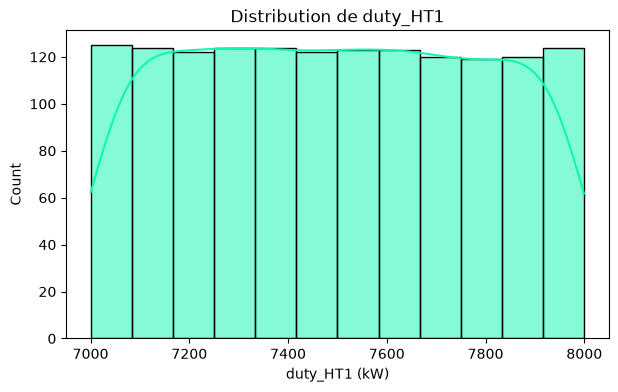

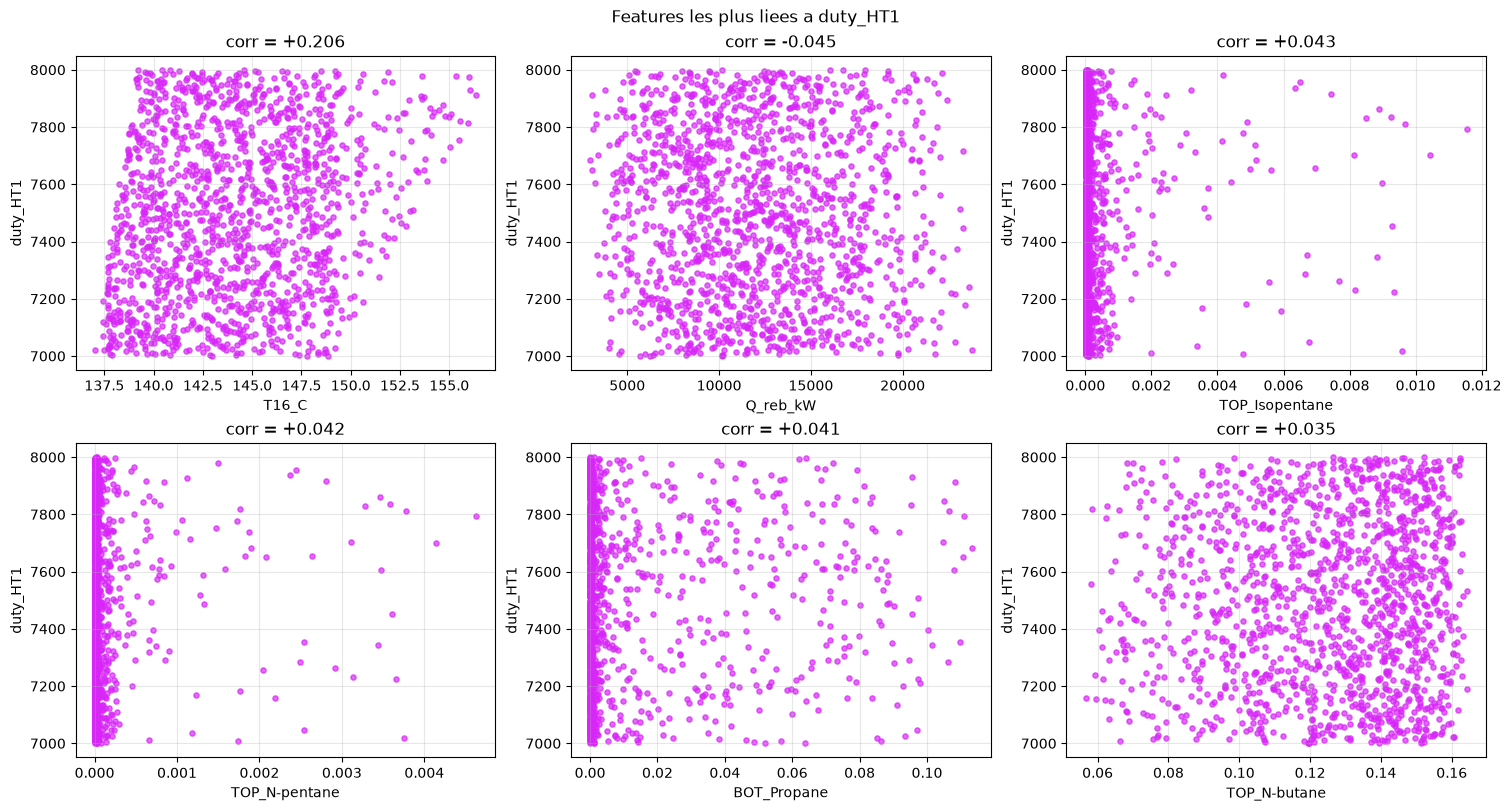

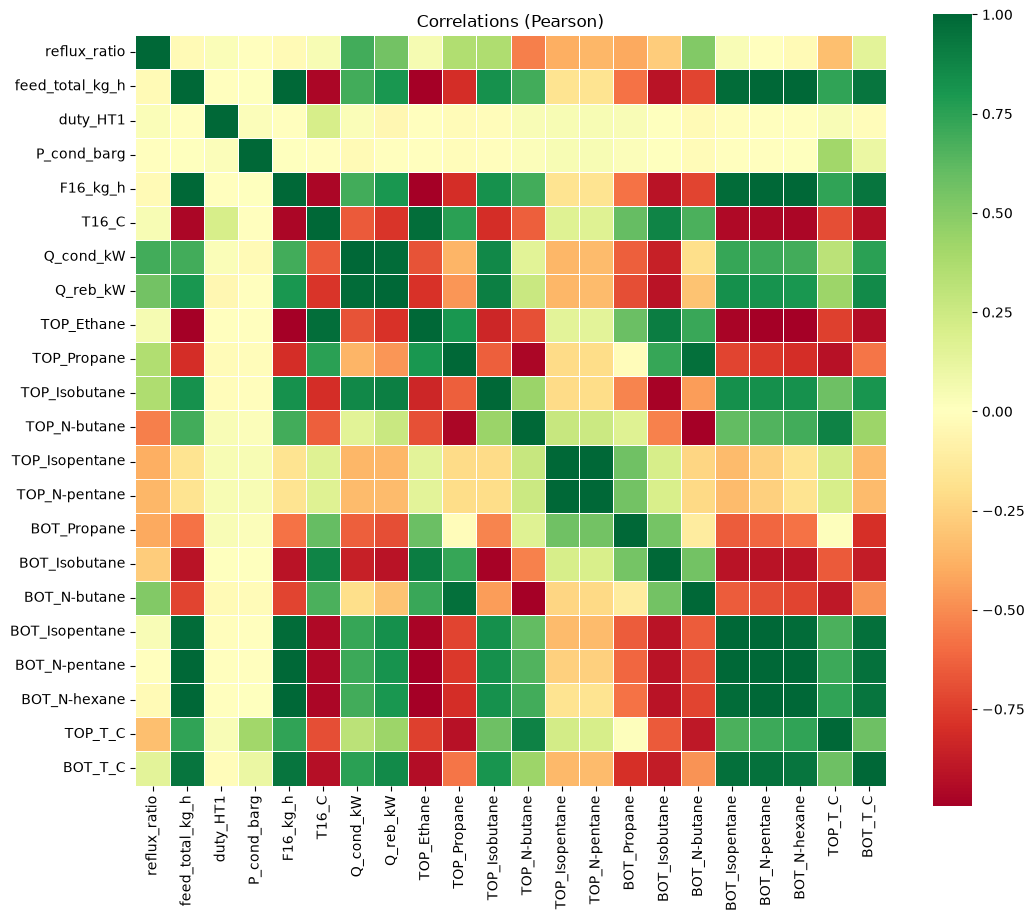

In [13]:
eda(df)

In [14]:
df['duty_HT1']

0       7146.094268
1       7774.825907
2       7453.086135
3       7387.037724
4       7628.114913
           ...     
1465    7875.448405
1466    7083.304851
1467    7719.261180
1468    7164.952026
1469    7705.425842
Name: duty_HT1, Length: 1470, dtype: float64

# building graphs for the DeepLearnig model GNN:
**building graphs for each features and others by calculate the correlation between them and the target**

In [15]:
def build_feature_graph(X_train, y_train):
    feats = list(X_train.columns)
    n = len(feats)
    corr = X_train.corr(method="spearman").abs().values.copy()
    np.fill_diagonal(corr, 0.0)
    adj = np.zeros((n, n))
    for i in range(n):
        for j in np.argsort(-corr[i])[:GRAPH_TOPK]:
            if corr[i, j] >= GRAPH_MIN_CORR:
                adj[i, j] = adj[j, i] = corr[i, j]
    G = nx.from_numpy_array(adj)
    G = nx.relabel_nodes(G, {i: f for i, f in enumerate(feats)})
    corr_target = {f: abs(X_train[f].corr(y_train, method="spearman")) for f in feats}
    nx.set_node_attributes(G, corr_target, "corr_target")
    return G, adj
def draw_graph(G, filename="graphe_features.png"):
    fig, ax = plt.subplots(figsize=(16, 12))
    pos = nx.spring_layout(G, seed=SEED, weight="weight",
                           k=3.0 / np.sqrt(max(len(G), 1)), iterations=300)
    node_vals = [G.nodes[n]["corr_target"] for n in G.nodes]
    widths = [0.5 + 4.0 * G[u][v]["weight"] for u, v in G.edges]
    nodes = nx.draw_networkx_nodes(G, pos, node_color=node_vals, cmap="viridis",
                                   vmin=0, vmax=max(max(node_vals), 0.3),
                                   node_size=700, ax=ax)
    nx.draw_networkx_edges(G, pos, width=widths, alpha=0.45, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax,
                            bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1.5))
    cbar = plt.colorbar(nodes, ax=ax, shrink=0.7)
    cbar.set_label(f"|Spearman| avec {TARGET_COL}")
    ax.set_title("Graphe des relations entre features "
                 f"(top-{GRAPH_TOPK} voisins, |corr| >= {GRAPH_MIN_CORR}) | "
                 f"{nx.number_connected_components(G)} composantes")
    ax.set_axis_off()


    edges = sorted(((u, v, d["weight"]) for u, v, d in G.edges(data=True)), key=lambda t: -t[2])
    pd.DataFrame(edges, columns=["feature_a", "feature_b", "abs_spearman"]).to_csv("graphe_aretes.csv", index=False)
    print("Correlation avec la cible (top 6):")
    for f, v in sorted(((n, G.nodes[n]["corr_target"]) for n in G.nodes), key=lambda t: -t[1])[:6]:
        print(f"  {f}: {v:.3f}")
    print("Aretes les plus fortes:")
    for u, v, w in edges[:8]:
        print(f"  {u} -- {v}: {w:.3f}")
    print(f"Noeuds: {G.number_of_nodes()} | aretes: {G.number_of_edges()}\n")

**preparing the data end drawing the graphs of the features**

X_train: (1176, 21) | X_test: (294, 21)

Correlation avec la cible (top 6):
  T16_C: 0.177
  TOP_N-pentane: 0.058
  TOP_Isopentane: 0.058
  TOP_T_C: 0.053
  TOP_N-butane: 0.052
  BOT_N-butane: 0.050
Aretes les plus fortes:
  feed_total_kg_h -- F16_kg_h: 1.000
  feed_total_kg_h -- BOT_N-hexane: 1.000
  F16_kg_h -- BOT_N-hexane: 1.000
  TOP_Isopentane -- TOP_N-pentane: 1.000
  feed_total_kg_h -- TOP_Ethane: 0.999
  F16_kg_h -- TOP_Ethane: 0.999
  TOP_Ethane -- BOT_N-hexane: 0.999
  BOT_Isopentane -- BOT_N-pentane: 0.998
Noeuds: 21 | aretes: 39



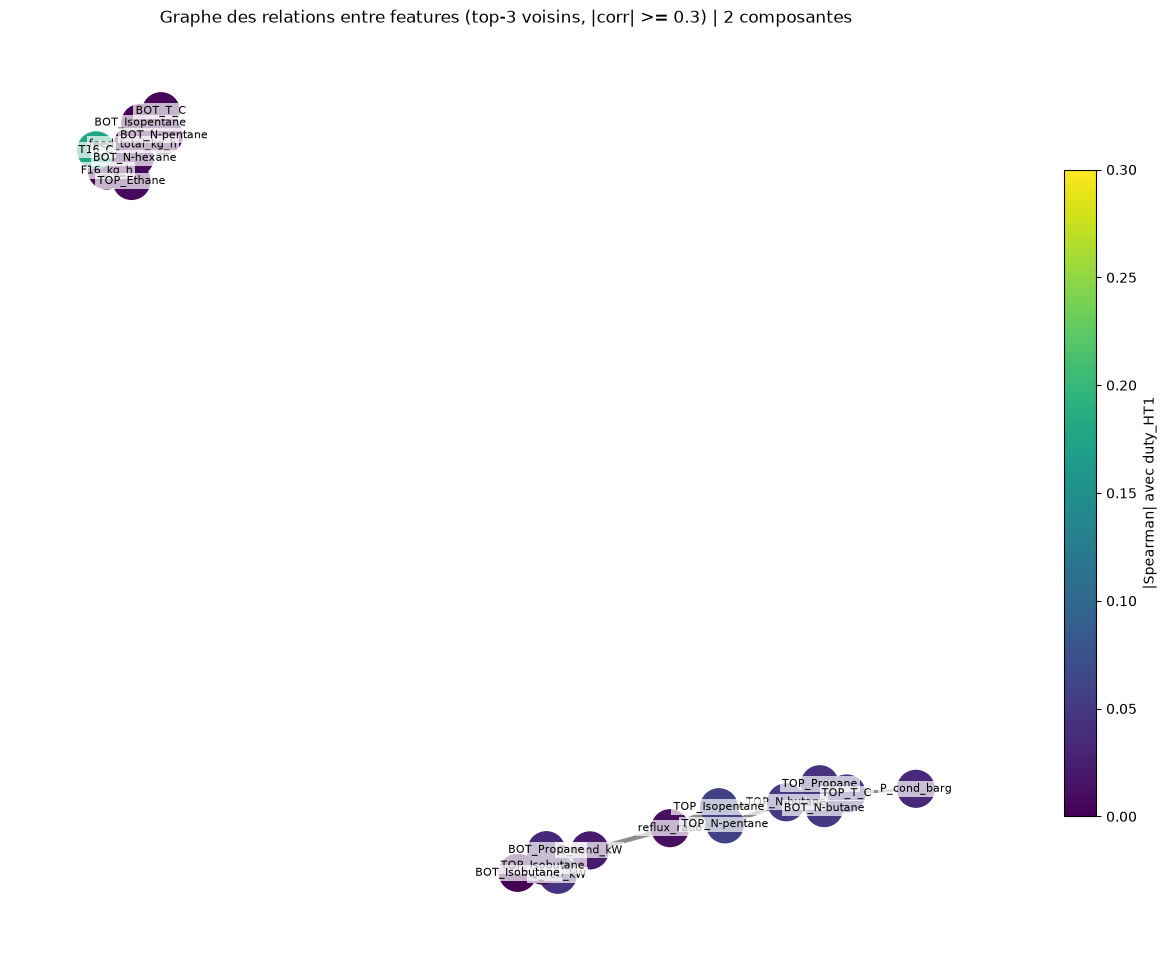

In [16]:
X = df.drop(columns = [TARGET_COL])
y =df[TARGET_COL]
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = TEST_SIZE , random_state = SEED)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}\n")

G , adj = build_feature_graph(X_train , y_train)
draw_graph(G)




**siting the ml models and there hyperaprametres**
**we will optimize this hyperparametres by optuna for a numbers of trials**

In [17]:
def build_model(name, params):
    if name == "XGBoost":
        return XGBRegressor(**params, random_state=SEED, n_jobs=N_JOBS, tree_method="hist")
    if name == "LightGBM":
        return LGBMRegressor(**params, random_state=SEED, n_jobs=N_JOBS, verbose=-1)

    raise ValueError(name)
def suggest_params(name, trial):
    if name == "XGBoost":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=100),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            "max_depth": trial.suggest_int("max_depth", 2, 6),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
        }
    if name == "LightGBM":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=100),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 4, 31),
            "min_child_samples": trial.suggest_int("min_child_samples", 3, 20),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
        }
    
    return {
        "iterations": trial.suggest_int("iterations", 100, 500, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "depth": trial.suggest_int("depth", 3, 6),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
    }

def make_objective(name, X, y):
    kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

    def objective(trial):
        model = build_model(name, suggest_params(name, trial))
        return cross_val_score(model, X, y, cv=kf, scoring="r2").mean()

    return objective



Il transforme chaque valeur en un vecteur (embedding).
Il fait échanger les noeuds voisins entre eux (message passing).
Il rassemble tous les noeuds pour prédire un nombre, le duty.

x                        (B, N)        valeurs standardisées des features
x.unsqueeze(-1)          (B, N, 1)
node_w + node_b        (B, N, H)     un vecteur de 32 nombres par noeud
couche 1 (lin, A, ...)   (B, N, H)
couche 2                 (B, N, H)
flatten(1)               (B, N*H)      tous les noeuds mis bout à bout
head                     (B, 1) -> squeeze -> (B,)   le duty prédit

In [18]:


class FeatureGraphNet(nn.Module):
    def __init__(self, n_nodes, adj_norm, hidden, n_layers, dropout):
        super().__init__()
        self.register_buffer("A", adj_norm)
        self.node_w = nn.Parameter(torch.randn(n_nodes, hidden) * 0.1)
        self.node_b = nn.Parameter(torch.zeros(n_nodes, hidden))
        self.lins = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(n_nodes * hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        h = x.unsqueeze(-1) * self.node_w + self.node_b
        for lin, norm in zip(self.lins, self.norms):
            m = torch.matmul(self.A, lin(h))
            h = h + self.drop(torch.relu(norm(m)))
        return self.head(h.flatten(1)).squeeze(-1)



def normalize_adjacency(adj):
    a = adj + np.eye(adj.shape[0])
    d = a.sum(axis=1)
    return a / np.sqrt(np.outer(d, d))
    

reshaping the y output to 2D  , and because the value are so different and scaled by all the features we have to doing a normalisation 

X_norm = (X - u)/sigma


for al the features has a limited value bitween 0 and 1 and 0.5 and the medium 

In [19]:


def train_gnn(X_train, y_train, X_test, adj, label , return_model = True):
    set_seed()
    sx = StandardScaler().fit(X_train.values)
    sy = StandardScaler().fit(y_train.values.reshape(-1, 1))
    Xs = sx.transform(X_train.values).astype(np.float32)
    ys = sy.transform(y_train.values.reshape(-1, 1)).ravel().astype(np.float32)
    Xt = torch.tensor(sx.transform(X_test.values), dtype=torch.float32)

    X_tr, X_va, y_tr, y_va = train_test_split(Xs, ys, test_size=VAL_SIZE, random_state=SEED)
    X_tr, X_va = torch.tensor(X_tr), torch.tensor(X_va)
    y_tr, y_va = torch.tensor(y_tr), torch.tensor(y_va)

    a_norm = torch.tensor(normalize_adjacency(adj), dtype=torch.float32)
    model = FeatureGraphNet(Xs.shape[1], a_norm, GNN_HIDDEN, GNN_LAYERS, GNN_DROPOUT)
    opt = torch.optim.AdamW(model.parameters(), lr=GNN_LR, weight_decay=GNN_WD)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=20)
    loss_fn = nn.MSELoss()

    best_val, best_state, wait = float("inf"), None, 0
    hist = {"train": [], "val": []}
    for epoch in range(GNN_EPOCHS):
        model.train()
        perm = torch.randperm(len(X_tr))
        run = 0.0
        for i in range(0, len(X_tr), GNN_BATCH):
            idx = perm[i:i + GNN_BATCH]
            if len(idx) < 2:
                continue
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
            run += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(X_va), y_va).item()
        sched.step(val)
        hist["train"].append(run / len(X_tr))
        hist["val"].append(val)
        if val < best_val - 1e-5:
            best_val = val
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= GNN_PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred = model(Xt).numpy()
    pred = sy.inverse_transform(pred.reshape(-1, 1)).ravel()

    print(f"  {label}: {len(hist['val'])} epoques, meilleure val MSE (std) = {best_val:.5f}")
    if return_model :
    
        return pred, hist , model , sx , sy 
    


In [20]:
def score(name, y_true, y_pred, cv_r2=np.nan):
    return {
        "model": name,
        "cv_R2": cv_r2,
        "test_R2": r2_score(y_true, y_pred),
        "test_MAE_kW": mean_absolute_error(y_true, y_pred),
        "test_RMSE_kW": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }



**ploting the results**

In [21]:
def plot_predictions(y_test, preds, results):
    r2 = {r["model"]: r["test_R2"] for r in results}
    names = list(preds.keys())
    ncols = 3
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 5 * nrows), constrained_layout=True)
    axes = np.atleast_1d(axes).flatten()
    lo, hi = float(y_test.min()), float(y_test.max())
    for name, ax in zip(names, axes):
        ax.scatter(y_test, preds[name], s=18, alpha=0.7, color=CYAN)
        ax.plot([lo, hi], [lo, hi], "r--", linewidth=1.3)
        ax.set_xlabel("duty HT-1 reel (kW)")
        ax.set_ylabel("duty HT-1 predit (kW)")
        ax.set_title(f"{name}\nR2 = {r2[name]:.4f}")
        ax.grid(True, alpha=0.3)
    for ax in axes[len(names):]:
        ax.axis("off")
    fig.suptitle("Predictions vs realite (jeu de test)", fontweight="bold")
  


In [22]:

def plot_comparison(results):
    df = pd.DataFrame(results).sort_values("test_R2")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    axes[0].barh(df["model"], df["test_R2"], color=PURPLE)
    axes[0].set_xlabel("R2 (test)")
    axes[0].set_title("R2")
    axes[1].barh(df["model"], df["test_MAE_kW"], color=YELLOW)
    axes[1].set_xlabel("MAE (kW)")
    axes[1].set_title("Erreur absolue moyenne")


In [23]:
def plot_gnn_history(histories):
    plt.figure(figsize=(8, 5))
    for label, h in histories.items():
        plt.plot(h["val"], label=f"{label} (val)")
        plt.plot(h["train"], "--", alpha=0.6, label=f"{label} (train)")
    plt.yscale("log")
    plt.xlabel("Epoque")
    plt.ylabel("MSE (cible standardisee)")
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.title("Courbes d'apprentissage GNN")



def plot_importance(model, X_test, y_test, name):
    imp = permutation_importance(model, X_test, y_test, n_repeats=15,
                                 random_state=SEED, scoring="r2")
    s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(12)
    plt.figure(figsize=(8, 6))
    plt.barh(s.index, s.values, color=CYAN)
    plt.xlabel("Baisse de R2 (permutation)")
    plt.title(f"Importance des features - {name}")
   

**preparation of  the data**

In [24]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)

In [27]:
results, preds, tuned = [], {}, {}


for name in TWO_MODELS:
    print(f"Optimisation {name} ({N_TRIALS} essais)...")
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(make_objective(name, X_train, y_train), n_trials=N_TRIALS)
    print(f"  CV R2 = {study.best_value:.5f} | params = {study.best_params}")
    model = build_model(name, study.best_params).fit(X_train, y_train)
    tuned[name] = model
    preds[name] = model.predict(X_test)
    results.append(score(name, y_test, preds[name], study.best_value))

Optimisation XGBoost (20 essais)...
  CV R2 = 0.96637 | params = {'n_estimators': 400, 'learning_rate': 0.10616701739126523, 'max_depth': 4, 'subsample': 0.7203898734604084, 'colsample_bytree': 0.9379338151451567, 'reg_lambda': 0.10499830756428262}
Optimisation LightGBM (20 essais)...
  CV R2 = 0.96777 | params = {'n_estimators': 300, 'learning_rate': 0.09958315786637538, 'num_leaves': 13, 'min_child_samples': 3, 'reg_lambda': 9.756667137604664}


In [ ]:
print("\nEntrainement GNN...")
histories = {}

preds["GNN (sans aretes)"], histories["sans aretes"] = train_gnn(
    X_train, y_train, X_test, np.zeros_like(adj), "GNN sans aretes (ablation)")
results.append(score("GNN (sans aretes)", y_test, preds["GNN (sans aretes)"]))



Entrainement GNN...


**Use a Linear regular regression model because we found the relationship between the targust and the features is definitly linear because the importante faetures is duty ≈ F16 × cp × (T16 − T15a)**

In [28]:
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-4, 3, 30)))
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_ridge = cross_val_score(ridge, X_train, y_train, cv=kf, scoring="r2").mean()
ridge.fit(X_train, y_train)
preds["Ridge"] = ridge.predict(X_test)
results.append(score("Ridge", y_test, preds["Ridge"], cv_ridge))

In [31]:
table = pd.DataFrame(results).sort_values("test_R2", ascending=False)
print("\n=== RESULTATS (jeu de test) ===")
print(table.round(5).to_string(index=False))
table.to_csv( "resultats_modeles.csv", index=False)



=== RESULTATS (jeu de test) ===
   model   cv_R2  test_R2  test_MAE_kW  test_RMSE_kW
   Ridge 0.99969  0.99977      3.18417       4.46781
 XGBoost 0.96637  0.97367     37.72567      47.46450
LightGBM 0.96777  0.97335     38.32871      47.74808


Le graphe de GNN dégrade le résultat. Il fait mélanger des features utiles (T16_C, F16_kg_h) avec d’autres qui sont corrélées entre elles mais peu liées au duty. Le signal utile se dilue.
Ridge est le meilleur (R² = 0,9998, MAE = 3,2 kW), car la relation est quasi linéaire (`duty ≈ F16 · cp · (T16 − T15a)`). 
Les arbres (XGBoost, LightGBM) restent derrière Les arbres prédisent par découpages successifs avec une valeur constante par feuille. Sur une relation quasi linéaire et un petit jeu de données, cette approximation en paliers est grossière, d’où l’avantage du modèle linéaire. »


Apport du graphe (R2 GNN graphe - R2 GNN sans aretes): -0.00289
Resultats dans: C:\Users\pc\Desktop\project\simulation chaine porduciton de ciment\resultats_ml


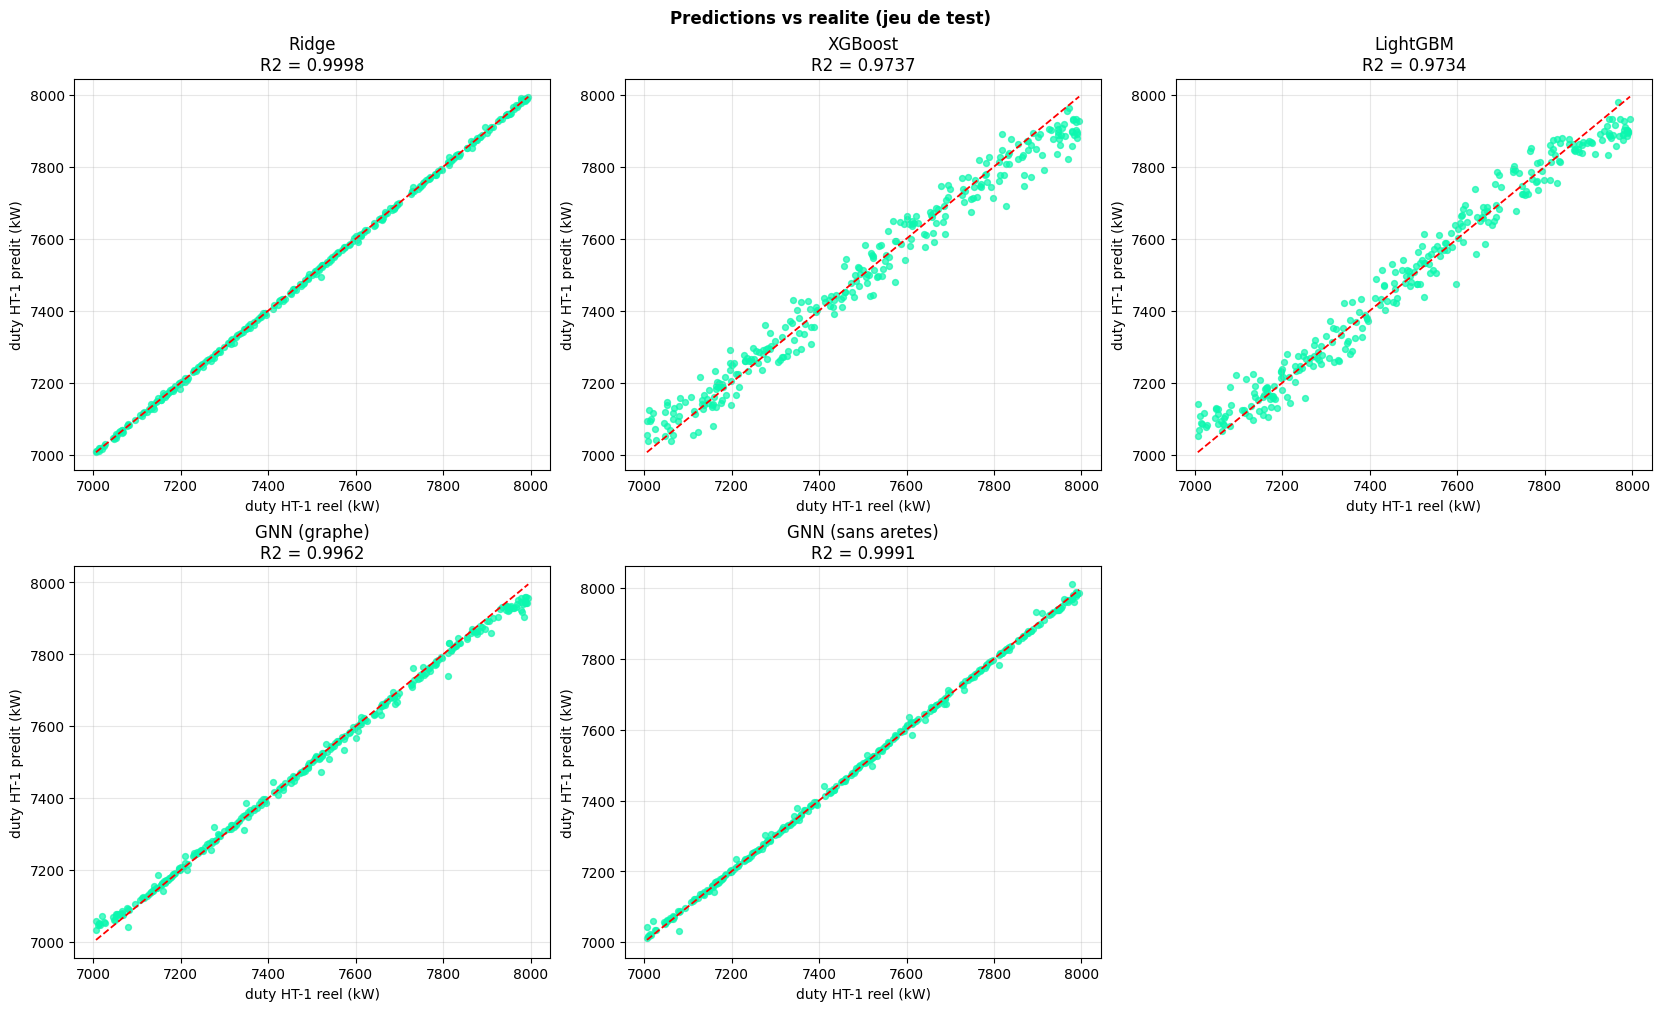

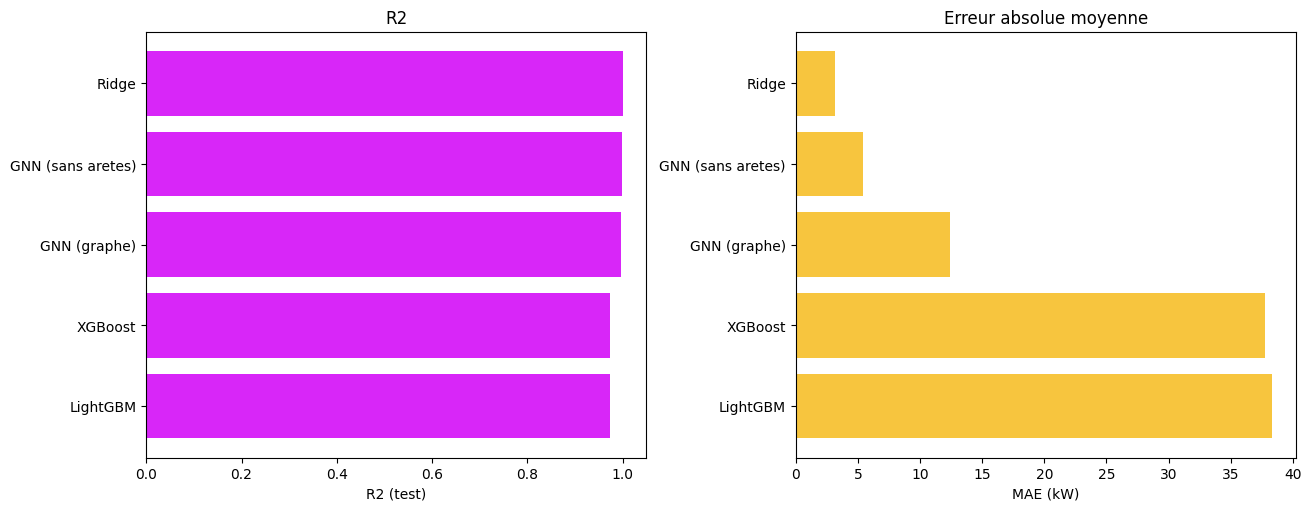

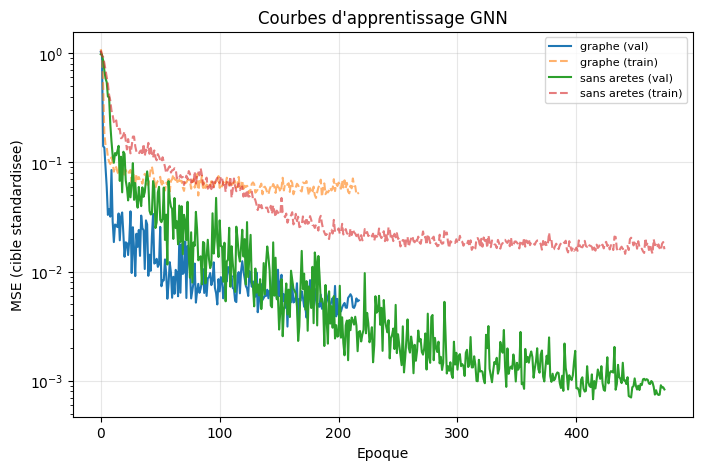

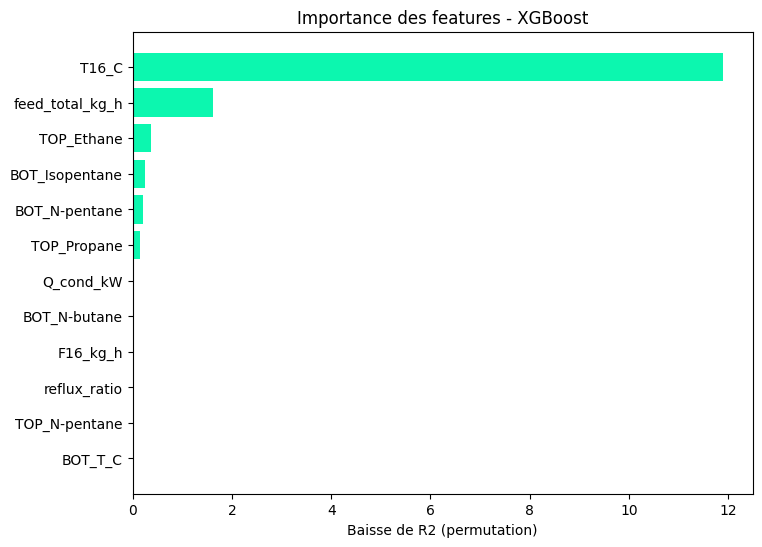

In [ ]:
plot_predictions(y_test, preds, results)
plot_comparison(results)
plot_gnn_history(histories)
best_tree = max(TWO_MODELS, key=lambda n: r2_score(y_test, preds[n]))
plot_importance(tuned[best_tree], X_test, y_test, best_tree)

gain = r2_score(y_test, preds["GNN (graphe)"]) - r2_score(y_test, preds["GNN (sans aretes)"])
print(f"\nApport du graphe (R2 GNN graphe - R2 GNN sans aretes): {gain:+.5f}")
print("Resultats dans:", OUT_DIR)

## Résultats

Les modèles ont été comparés sur le jeu de test pour estimer le duty de HT-1. **Ridge est le meilleur** (R² = 0,9998, MAE = 3,2 kW), car la relation est quasi linéaire (`duty ≈ F16 · cp · (T16 − T15a)`). Les arbres (XGBoost, LightGBM) restent derrière (R² ≈ 0,973, MAE ≈ 38 kW). Le GNN atteint un R² de 0,9991 sans arêtes et seulement 0,9962 avec le graphe de corrélations : ce graphe n'apporte donc rien, car il mélange les features utiles (`T16_C`, `F16_kg_h`) avec des variables peu liées au duty. Le modèle fonctionne comme un capteur virtuel inverse, qui retrouve le duty à partir de mesures en aval, surtout `T16_C`.



The general linear regression equation is:

$$
\hat{y} = \beta_0 + \sum_{j=1}^{p} \beta_j x_j
$$

Ridge regression uses L2 regularization to prevent overfitting by minimizing the following cost function:

$$
J(\beta) =
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\alpha \sum_{j=1}^{p}\beta_j^2
$$


**renforcé le model lineaire de rdgie par model ploynomiale**

In [ ]:

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

results = []

model_ridge_poly = make_pipeline(StandardScaler(),PolynomialFeatures(2, include_bias=False),StandardScaler(),RidgeCV(alphas=np.logspace(-4, 3, 30))
)

cv_ridge_poly = cross_val_score(model_ridge_poly,X_train,y_train,cv=kf,scoring="r2").mean()

model_ridge_poly.fit(X_train, y_train)

preds= model_ridge_poly.predict(X_test)

scores_poly = score("model_ridge_poly",y_test,preds,cv_r2=cv_ridge_poly)

results.append(scores_poly)

results_dataframe = pd.DataFrame(results).to_string(index=False)


In [ ]:
results_dataframe

'           model   cv_R2  test_R2  test_MAE_kW  test_RMSE_kW\nmodel_ridge_poly 0.99994 0.999981      0.63658      1.266558'


## 2. Ridge Polynomial Regression (Degree 2)

Polynomial regression of degree 2 introduces squared terms and interaction terms between input features.

The general equation is:

$$
\hat{y} =
\beta_0
+ \sum_{j=1}^{p}\beta_j x_j
+ \sum_{j=1}^{p}\beta_{jj}x_j^2
+ \sum_{j<k}\beta_{jk}x_jx_k
$$

Ridge Polynomial regression minimizes:

$$
J(\beta) =
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\alpha \sum_{j=1}^{m}\beta_j^2
$$




**Conclusion:** Ridge Linear models linear relationships, whereas Ridge Polynomial captures more complex nonlinear relationships by transforming the original features into polynomial features. Both models use L2 regularization to control overfitting.


In [ ]:
import os
import joblib

os.makedirs(OUT_DIR, exist_ok=True)
joblib.dump(
    {"model": model_ridge_poly, "features": list(X_train.columns)},
    os.path.join(OUT_DIR, "duty_model.joblib"),
)

['C:\\Users\\pc\\Desktop\\project\\simulation chaine porduciton de ciment\\resultats_ml\\ridge_modelamélioré.joblib']

**saving the ridge model linear model**

In [ ]:
import os
import joblib

os.makedirs(OUT_DIR, exist_ok=True)
joblib.dump(
    {"model": ridge, "features": list(X_train.columns)},
    os.path.join(OUT_DIR, "ridge_model.joblib"),
)


['C:\\Users\\pc\\Desktop\\project\\simulation chaine porduciton de ciment\\resultats_ml\\ridge_model.joblib']

In [ ]:
import torch

In [ ]:
import torch

pred, hist, gnn_model, sx, sy = train_gnn(
    X_train, y_train, X_test, np.zeros_like(adj),
    "GNN sans aretes", return_model=True)

torch.save({
    "state_dict": gnn_model.state_dict(),
    "features": list(X_train.columns),
    "config": {"n_nodes": int(X_train.shape[1]), "hidden": GNN_HIDDEN,
               "n_layers": GNN_LAYERS, "dropout": GNN_DROPOUT},
}, os.path.join(OUT_DIR, "gnn_sans_aretes.pt"))

joblib.dump({"sx": sx, "sy": sy}, os.path.join(OUT_DIR, "gnn_scalers.joblib"))



  GNN sans aretes: 475 epoques, meilleure val MSE (std) = 0.00068


['C:\\Users\\pc\\Desktop\\project\\simulation chaine porduciton de ciment\\resultats_ml\\gnn_scalers.joblib']

In [ ]:
X_train.columns

Index(['reflux_ratio', 'feed_total_kg_h', 'P_cond_barg', 'F16_kg_h', 'T16_C',
       'Q_cond_kW', 'Q_reb_kW', 'TOP_Ethane', 'TOP_Propane', 'TOP_Isobutane',
       'TOP_N-butane', 'TOP_Isopentane', 'TOP_N-pentane', 'BOT_Propane',
       'BOT_Isobutane', 'BOT_N-butane', 'BOT_Isopentane', 'BOT_N-pentane',
       'BOT_N-hexane', 'TOP_T_C', 'BOT_T_C'],
      dtype='object')